# Toy model ideas

In [40]:
import glob
import re
import itertools

import matplotlib.pyplot as plt
import scipy.signal
import seaborn as sns
import numpy as np
import pandas as pd

In [41]:
import bidict

In [9]:
import pymc as pm

In [10]:
import arviz as az

In [11]:
import pytensor as pt

In [12]:
from scipy import io

In [13]:
import os

Idea: 
 - focus on a single user for now
  -  estimate parameters from the non-intensive activities time series
  - build a model to predict/impute values for the intensive activities  

- restrict to z axis?
- restrict to accelometer?

## Data etc

In [14]:
phone_acc_df = pd.read_pickle('data/phone_acc_df.pkl')
phone_gyro_df = pd.read_pickle('data/phone_gyro_df.pkl')
watch_acc_df = pd.read_pickle('data/watch_acc_df.pkl')
watch_gyro_df = pd.read_pickle('data/watch_gyro_df.pkl')

In [15]:
activity_codes = bidict.bidict({
    'A': 'walking',
    'B': 'jogging',
    'C': 'stairs',
    'D': 'sitting',
    'E': 'standing',
    'F': 'typing',
    'G': 'teeth',
    'H': 'soup',
    'I': 'chips',
    'J': 'pasta',
    'K': 'drinking',
    'L': 'sandwich',
    'M': 'kicking',
    'O': 'catch',
    'P': 'dribbling',
    'Q': 'writing',
    'R': 'clapping',
    'S': 'folding'
})

In [16]:
activity_groups = {
    "non-hand": ['walking', 'jogging', 'stairs', 'standing', "kicking"],
    "hand": ["dribbling","catch", "typing", "writing", "clapping",  "teeth", "folding"],
    "hand-eating": ["soup", "chips", "pasta", "sandwich", "drinking"]
}

In [18]:
user_id = 1610

## Auxiliary features

In [22]:
idx_eat = phone_acc_df.loc[user_id, 'ACTIVITY'].isin({activity_codes.inverse[desc] for desc in activity_groups['hand-eating']}) 

df_eat = phone_acc_df.loc[user_id][idx_eat]

In [23]:
idx_act = phone_acc_df.loc[user_id, 'ACTIVITY'].isin({activity_codes.inverse[desc] for desc in activity_groups['hand']})

df_act = phone_acc_df.loc[user_id][idx_act]

<Axes: >

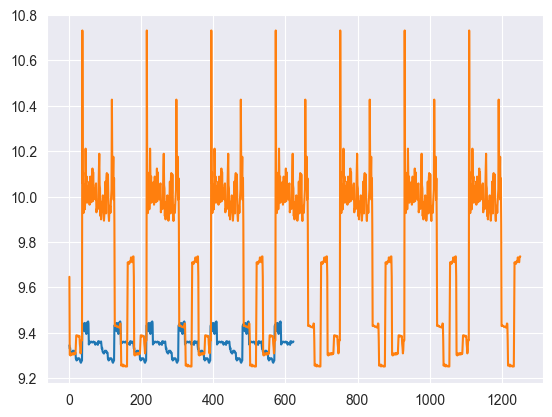

In [31]:
df_eat.reset_index()['RESULTANT'].plot()
df_act.reset_index()['RESULTANT'].plot()


In [47]:
eat_avgs  = df_eat.drop(columns="ACTIVITY").mean(axis=0)

`FIXME: what to do with the histogram features?`

In [54]:
eat_avgs

X0           0.000000
X1           0.000000
X2           0.000000
X3           0.000000
X4           0.201292
               ...   
YZCOS        0.594817
XYCOR       -0.191686
XZCOR       -0.471820
YZCOR       -0.125553
RESULTANT    9.347897
Length: 91, dtype: float64

In [43]:
scipy.signal.find_peaks(df_eat["RESULTANT"], prominence=0.1)

(array([ 52, 141, 230, 319, 408, 497, 586]),
 {'prominences': array([0.18211, 0.18211, 0.18211, 0.18211, 0.18211, 0.18211, 0.1032 ]),
  'left_bases': array([ 32, 121, 210, 299, 388, 477, 566]),
  'right_bases': array([121, 210, 299, 388, 477, 566, 613])})

In [45]:
df_eat["RESULTANT"].iloc[scipy.signal.find_peaks(df_eat["RESULTANT"], prominence=0.1)[0]
]

class
1610    9.44997
1610    9.44997
1610    9.44997
1610    9.44997
1610    9.44997
1610    9.44997
1610    9.44997
Name: RESULTANT, dtype: float64

In [46]:
def find_peak_mean(column, prominence=0.1):
        return column.iloc[scipy.signal.find_peaks(column, prominence=prominence)[0]].mean()


In [52]:
eat_peak_means = df_eat.drop(columns="ACTIVITY").apply(find_peak_mean, axis=0)

In [53]:
eat_peak_means

X0                NaN
X1                NaN
X2                NaN
X3                NaN
X4           1.000000
               ...   
YZCOS        0.999956
XYCOR        0.081228
XZCOR       -0.256704
YZCOR        0.189525
RESULTANT    9.449970
Length: 91, dtype: float64

## Model 1

Bayesian filtering/forecasting

In [55]:
with pm.Model() as model:
    # Priors
    mu = pm.Normal('mu', mu=0, sigma=1)
    sigma = pm.HalfNormal('sigma', sigma=1)
    
    # Likelihood
    likelihood = pm.Normal('likelihood', mu=mu, sigma=sigma, observed=eat_avgs)
    
    # Posterior
    trace = pm.sample(1000, tune=1000)

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.
